# Autonomous Tabular Data Analysis with LangChain Pandas Agent

In this notebook, we explore how Large Language Models (LLMs) can act as autonomous data analysts over tabular datasets using **LangChain's Pandas DataFrame Agent**.

### Key Concepts Covered:
1. **ReAct Loop & Python REPL**: How LLMs plan actions, write Python code, execute it against a live Pandas DataFrame, observe stdout/results, and synthesize a final answer.
2. **Single & Multi-DataFrame Reasoning**: Performing complex filtering, aggregations, cross-table joins, and statistical analysis.
3. **Automated Visualization**: Generating publication-quality charts (heatmaps, bar plots) on demand.
5. **Robust Parsing & Safety**: Handling parsing edge cases (`handle_parsing_errors=True`) and sandboxing code execution (`allow_dangerous_code=True`).

In [1]:
# Install required packages if not already present
#!pip install -U langchain langchain-experimental langchain-openai pandas seaborn matplotlib pyyaml


## 1. Environment & LLM Setup

We initialize our OpenAI-compatible client pointed at the local Ollama server, with the model and URL read from `config.yaml` like the other week 7 notebooks.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
with warnings.catch_warnings():   # langchain-experimental warns it is being sunset; still works for this demo
    warnings.simplefilter("ignore", DeprecationWarning)
    from langchain_experimental.agents import create_pandas_dataframe_agent
import yaml
from langchain_openai import ChatOpenAI

cfg = yaml.safe_load(open("config.yaml"))

# Ollama serves an OpenAI-compatible API under /v1; settings come from config.yaml
model_name = cfg["ollama"]["langchain_model"]   # larger than the Strands model: see config.yaml
base_url = cfg["ollama"]["url"].rstrip("/") + "/v1"

print(f"Initializing LLM: {model_name} (Base URL: {base_url})")
llm = ChatOpenAI(
    model=model_name,
    temperature=0.0,
    base_url=base_url,
    api_key="ollama",           # ignored by Ollama, required by the client
    max_retries=2,
)


Initializing LLM: gemma4:e4b-mlx (Base URL: http://localhost:11434/v1)


## 2. Preparing the Sample Dataset

We create one realistic dataset, **`df_sales`**: e-commerce transactions with customer IDs, categories, unit prices, and satisfaction ratings.

In [3]:
# E-Commerce Transactions
np.random.seed(42)
n_records = 200
categories = ["Electronics", "Home & Kitchen", "Books", "Clothing", "Health"]
regions = ["North America", "Europe", "Asia-Pacific", "Latin America"]

df_sales = pd.DataFrame({
    "order_id": [f"ORD-{1000 + i}" for i in range(n_records)],
    "customer_id": [f"CUST-{np.random.randint(100, 150)}" for _ in range(n_records)],
    "category": np.random.choice(categories, size=n_records, p=[0.3, 0.25, 0.2, 0.15, 0.1]),
    "region": np.random.choice(regions, size=n_records),
    "quantity": np.random.randint(1, 10, size=n_records),
    "unit_price": np.round(np.random.exponential(scale=50, size=n_records) + 5, 2),
    "rating": np.random.choice([1, 2, 3, 4, 5, np.nan], size=n_records, p=[0.05, 0.1, 0.2, 0.35, 0.25, 0.05])
})
df_sales["total_revenue"] = np.round(df_sales["quantity"] * df_sales["unit_price"], 2)

print("Sales Transactions Sample:")
print(df_sales.head(3))

Sales Transactions Sample:
   order_id customer_id        category         region  quantity  unit_price  \
0  ORD-1000    CUST-138          Health  North America         7        9.84   
1  ORD-1001    CUST-128  Home & Kitchen   Asia-Pacific         8       37.81   
2  ORD-1002    CUST-114  Home & Kitchen  North America         9       63.20   

   rating  total_revenue  
0     3.0          68.88  
1     3.0         302.48  
2     5.0         568.80  


## 3. Creating the Single-DataFrame Agent

A small local Ollama model is unreliable with LangChain's default text-based ReAct format: it invents `Observation:` lines instead of waiting for the tool. So we use `agent_type="tool-calling"`, which uses the model's native tool calling like the Strands notebooks do. LangChain's text-to-code loop also needs a slightly larger model than the Strands notebooks: `ollama.langchain_model` in `config.yaml` (`gemma4:e4b-mlx`). The smaller default model often answered from the data preview (for example "5 rows" for a 200-row table).

> **Crucial Parameters**:
> - `agent_type="tool-calling"`: structured tool calls instead of parsing free text.
> - `allow_dangerous_code=True`: Required by LangChain to acknowledge that executing arbitrary Python code generated by the LLM runs locally.
> - `max_iterations=5`: Prevents infinite loops if an agent gets stuck.
> - `prefix`: tells the model the dataframes are already loaded and to compute answers with the Python tool instead of guessing from, or retyping, the preview it is shown. It also says the tool returns only the value of the last expression (LangChain's Python tool drops earlier `print()` output, which made the model report wrong numbers).

In [4]:
PREFIX = ("You are working with pandas dataframes that are ALREADY loaded in the python tool as variables "
          "(df, or df1, df2, ...). Never recreate or retype the data. Always compute answers by running code with "
          "the python tool; never answer from the preview of the data. The tool returns only the value of the LAST "
          "expression, so do not use print(): end the code with one expression, for example a tuple or dict "
          "holding every number you need. "
          "Pass the code in the tool's `query` argument.")

def make_agent(df):
    return create_pandas_dataframe_agent(
        llm=llm,
        df=df,
        agent_type="tool-calling",
        prefix=PREFIX,
        verbose=True,
        allow_dangerous_code=True,
        max_iterations=5,
    )

sales_agent = make_agent(df_sales)

### 3.1 Basic Dataset Introspection & Descriptive Statistics

In [5]:
# Query 1: Basic row and column count
response_1 = sales_agent.invoke("How many total rows and columns are in the dataframe, and what are the column names?")
print("\nFinal Answer:", response_1["output"])



> Entering new AgentExecutor chain...

Invoking: `python_repl_ast` with `{'query': 'print(df.shape)\nprint(df.columns.tolist())'}`


(200, 8)
['order_id', 'customer_id', 'category', 'region', 'quantity', 'unit_price', 'rating', 'total_revenue']

Invoking: `python_repl_ast` with `{'query': 'print(df.shape)'}`
responded: The dataframe has 8 columns: `order_id`, `customer_id`, `category`, `region`, `quantity`, `unit_price`, `rating`, and `total_revenue`.

To provide the total number of rows and columns, I need the output of `df.shape`. I will run a query to get that.



(200, 8)
The dataframe has 200 rows and 8 columns.

The column names are: `order_id`, `customer_id`, `category`, `region`, `quantity`, `unit_price`, `rating`, and `total_revenue`.

> Finished chain.

Final Answer: The dataframe has 200 rows and 8 columns.

The column names are: `order_id`, `customer_id`, `category`, `region`, `quantity`, `unit_price`, `rating`, and `total_revenue`.


In [6]:
# Query 2: Grouped statistical summary
response_2 = sales_agent.invoke("What is the average unit_price and average quantity for each distinct category?")
print("\nFinal Answer:", response_2["output"])



> Entering new AgentExecutor chain...

Invoking: `python_repl_ast` with `{'query': "df.groupby('category')[['unit_price', 'quantity']].mean()"}`


                unit_price  quantity
category                            
Books            52.368958  4.520833
Clothing         73.585000  4.961538
Electronics      57.491500  4.600000
Health           46.744286  5.142857
Home & Kitchen   47.114667  4.777778The average unit price and average quantity for each distinct category are:

| Category | Average Unit Price | Average Quantity |
| :--- | :--- | :--- |
| Books | 52.368958 | 4.520833 |
| Clothing | 73.585000 | 4.961538 |
| Electronics | 57.491500 | 4.600000 |
| Health | 46.744286 | 5.142857 |
| Home & Kitchen | 47.114667 | 4.777778 |

> Finished chain.

Final Answer: The average unit price and average quantity for each distinct category are:

| Category | Average Unit Price | Average Quantity |
| :--- | :--- | :--- |
| Books | 52.368958 | 4.520833 |
| Clothing | 73.585000 | 4.961538 |


## 4. Complex Business Analytics on Sales Data

In [7]:
# Query 3: Multi-step aggregation & revenue calculation
query = """
Find the top 3 product categories by total revenue.
For each of these top 3 categories, calculate the total quantity sold and the average customer rating.
"""
response_3 = sales_agent.invoke(query)
print("\nFinal Answer:", response_3["output"])



> Entering new AgentExecutor chain...

Invoking: `python_repl_ast` with `{'query': "top_3_categories = df.groupby('category').agg(\n    total_revenue=('total_revenue', 'sum'),\n    total_quantity=('quantity', 'sum'),\n    average_rating=('rating', 'mean')\n).reset_index()\ntop_3_categories = top_3_categories.sort_values(by='total_revenue', ascending=False).head(3)\ntop_3_categories"}`


         category  total_revenue  total_quantity  average_rating
2     Electronics       13953.36             276           4.000
0           Books       10743.60             217           4.000
4  Home & Kitchen       10247.27             215           3.625The top 3 product categories by total revenue, along with their total quantity sold and average customer rating, are:

| Category | Total Revenue | Total Quantity Sold | Average Rating |
| :--- | :--- | :--- | :--- |
| Electronics | 13953.36 | 276 | 4.000 |
| Books | 10743.60 | 217 | 4.000 |
| Home & Kitchen | 10247.27 | 215 | 3.625 |

> Finished 

In [8]:
# Query 4: Handling missing values
response_4 = sales_agent.invoke("How many missing values are in the rating column, and what is the median rating when ignoring nulls?")
print("\nFinal Answer:", response_4["output"])



> Entering new AgentExecutor chain...

Invoking: `python_repl_ast` with `{'query': "missing_count = df['rating'].isnull().sum()\nmedian_rating = df['rating'].median()\nprint((missing_count, median_rating))"}`


(np.int64(13), np.float64(4.0))
There are 13 missing values in the `rating` column, and the median rating (ignoring nulls) is 4.0.

> Finished chain.

Final Answer: There are 13 missing values in the `rating` column, and the median rating (ignoring nulls) is 4.0.


## 5. Automated Data Visualization

Because the Python REPL tool executes in the local environment, the agent can import `matplotlib` and `seaborn` to generate and render inline plots directly.



> Entering new AgentExecutor chain...


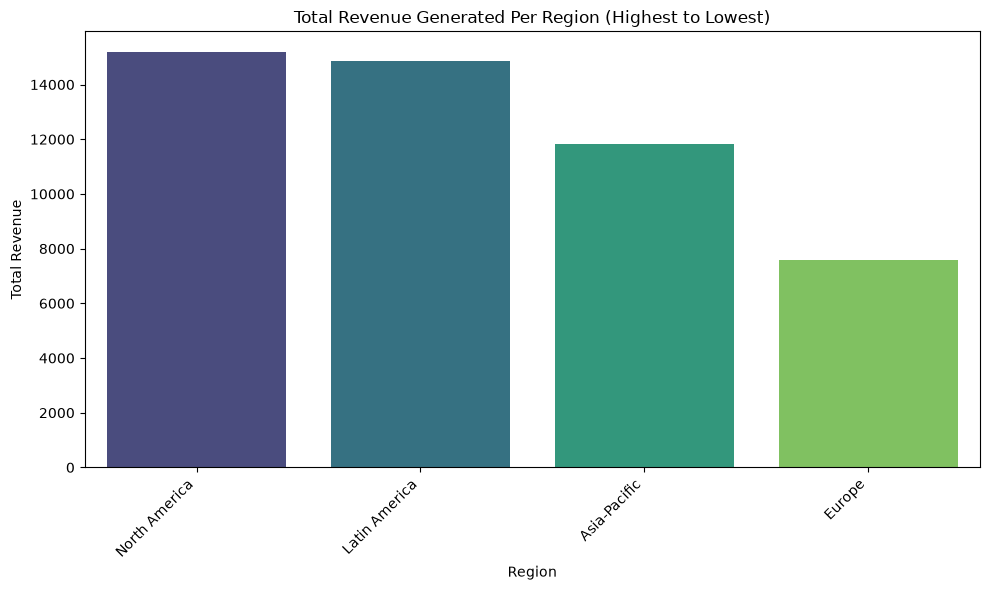


Invoking: `python_repl_ast` with `{'query': "import seaborn as sns\nimport matplotlib.pyplot as plt\n\n# Calculate total revenue per region and sort\nrevenue_by_region = df.groupby('region')['total_revenue'].sum().sort_values(ascending=False)\n\n# Create the bar plot\nplt.figure(figsize=(10, 6))\nsns.barplot(x=revenue_by_region.index, y=revenue_by_region.values, hue=revenue_by_region.index, palette='viridis', dodge=False)\n\n# Add title and customize\nplt.title('Total Revenue Generated Per Region (Highest to Lowest)')\nplt.xlabel('Region')\nplt.ylabel('Total Revenue')\nplt.legend([],[], frameon=False) # Setting legend to False\nplt.xticks(rotation=45, ha='right')\nplt.tight_layout()\n\n# Show the plot\nplt.show()"}`


The bar plot showing total revenue generated per region, sorted from highest to lowest, has been created and displayed.

> Finished chain.


{'input': '\nCreate a bar plot showing total revenue generated per region, sorted from highest to lowest.\nUse seaborn with x=region, y=total revenue, hue=region, legend=False, palette viridis, add a title, and call plt.show().\n',
 'output': 'The bar plot showing total revenue generated per region, sorted from highest to lowest, has been created and displayed.'}

In [9]:
# Query 5: Visualizing distributions and correlations
plot_query = """
Create a bar plot showing total revenue generated per region, sorted from highest to lowest.
Use seaborn with x=region, y=total revenue, hue=region, legend=False, palette viridis, add a title, and call plt.show().
"""
sales_agent.invoke(plot_query)

## 6. Multi-DataFrame Agent (Relational Reasoning)

When passed a list of dataframes `[df1, df2]`, the agent can reference `df1` and `df2` simultaneously to perform relational merges and cross-table analytics.

In [10]:
# Create auxiliary customer profile table
unique_customers = df_sales["customer_id"].unique()
df_customers = pd.DataFrame({
    "customer_id": unique_customers,
    "membership_tier": np.random.choice(["Gold", "Silver", "Bronze", "Platinum"], size=len(unique_customers)),
    "signup_year": np.random.choice([2021, 2022, 2023, 2024], size=len(unique_customers))
})

# Create multi-dataframe agent
multi_agent = make_agent([df_sales, df_customers])

# Query across both tables
multi_query = """
Merge df1 (sales) and df2 (customers) on customer_id.
Which membership_tier generated the highest average total revenue per transaction?
"""
response_multi = multi_agent.invoke(multi_query)
print("\nFinal Answer:", response_multi["output"])



> Entering new AgentExecutor chain...

Invoking: `python_repl_ast` with `{'query': "import pandas as pd\n\n# Merge the dataframes\nmerged_df = pd.merge(df1, df2, on='customer_id')\n\n# Calculate the average total revenue per membership tier\naverage_revenue_by_tier = merged_df.groupby('membership_tier')['total_revenue'].mean()\n\n# Find the membership tier with the highest average revenue\nhighest_tier = average_revenue_by_tier.idxmax()\n\nhighest_average = average_revenue_by_tier.max()\n\nprint((highest_tier, highest_average))"}`


('Silver', np.float64(271.47054545454546))
The membership tier that generated the highest average total revenue per transaction is **Silver**.

> Finished chain.

Final Answer: The membership tier that generated the highest average total revenue per transaction is **Silver**.


## 7. Summary & Best Practices

1. **Execution Safety**: Always run code execution agents in an isolated sandbox or container in production.
2. **Prompt Robustness**: Native tool calling (`agent_type="tool-calling"`) avoids the text-parsing failures that small local models hit with ReAct, and a prefix that says "compute, do not guess" cuts wrong answers. Small models can still slip, so check the generated code.
3. **Structured vs Natural Language**: For clean schema analytics, combining Python REPL agents with deterministic aggregations provides explainability through direct inspection of the generated Python code.
4. **Multi-Table Scenarios**: When datasets exceed memory constraints, prefer Text-to-SQL agents (covered in `7.5-Agent-Database.ipynb`).